# 04 — Нейросеть Double DQN и подбор гиперпараметров

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from simulator import *
from agents import *
from experiments import *
assert Path('data/processed.npz').exists(), 'Сначала выполните data_pipeline.py'
data=load_data()
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.2})


Настоящая полносвязная нейросеть: 10 → hidden → hidden → 3, ReLU. Три выхода оценивают действия −1/0/+1. Реализация NumPy с обратным распространением, Adam, Huber loss, clipping нормы градиента 10, replay buffer 20000 и отдельной target network. Double DQN выбирает следующее действие основной сетью, а оценивает целевой.

Входы: число шардов; прошлое число запросов; прошлый максимум загрузки; средняя нагрузка четырёх прошлых интервалов; тренд; sin/cos времени суток; текущий объём живых данных; цена переноса при сокращении/расширении. Все наблюдения доступны до решения. Масштабы вычислены по train или фиксированы. Состояние всё ещё неполное: в нём нет полного распределения ключей и будущих TTL.

12 вариантов: hidden 32/64, learning rate 0.0003/0.001, gamma 0.90/0.97/0.99. Предварительное обучение 160 эпизодов с seed 7. Три лучших варианта обучаются 400 эпизодов с seed 7/42/123. Checkpoint каждые 40 эпизодов выбирается по validation. Гиперпараметры выбираются по средней validation cost трёх seed, потом выбирается лучший validation seed. Batch 64, обновление каждые 4 шага после 256 наблюдений, target обновляется каждые 256 шагов. Reward делится на 10 только для устойчивости обучения; итоговая стоимость не масштабируется. Epsilon линейно снижается до 0.03 за 80% обучения.

Подбор весов — это обучение градиентами, а не ручной подбор. Перебор не гарантирует глобального оптимума. Настройка по одному дню validation не заменяет независимую проверку на других неделях.

In [2]:
# Готовые результаты загружаются. Полный повтор: retrain=True.
finalists=run_dqn_study(retrain=False)
display(pd.read_csv('results/dqn/screen.csv'))
display(finalists)
display(finalists.groupby('trial').validation_cost.agg(['mean','std']))
selected=json.loads(Path('results/dqn/selection.json').read_text())
display(pd.Series(selected))
net=MLP.load('results/dqn/'+selected['name']+'.npz')
print('Обучаемых параметров:',sum(p.size for p in net.p))

,trial,hidden,lr,gamma,target_interval,validation_cost
0,0,32,0.0003,0.90,256,1180.200778
1,1,32,0.0003,0.97,256,1184.329622
2,2,32,0.0003,0.99,256,1168.507055
3,3,32,0.0010,0.90,256,1177.099782
4,4,32,0.0010,0.97,256,1183.885736
5,5,32,0.0010,0.99,256,1201.268205
6,6,64,0.0003,0.90,256,1180.988369
7,7,64,0.0003,0.97,256,1176.444751
8,8,64,0.0003,0.99,256,1167.443966
9,9,64,0.0010,0.90,256,1174.917840


,name,trial,seed,hidden,lr,gamma,target_interval,validation_cost,best_episode
0,trial_8_seed_7,8,7,64,0.0003,0.99,256,1161.156419,360
1,trial_8_seed_42,8,42,64,0.0003,0.99,256,1199.557516,40
2,trial_8_seed_123,8,123,64,0.0003,0.99,256,1186.434897,40
3,trial_2_seed_7,2,7,32,0.0003,0.99,256,1168.990500,240
4,trial_2_seed_42,2,42,32,0.0003,0.99,256,1182.772313,200
5,trial_2_seed_123,2,123,32,0.0003,0.99,256,1206.574547,160
6,trial_9_seed_7,9,7,64,0.0010,0.90,256,1167.780269,320
7,trial_9_seed_42,9,42,64,0.0010,0.90,256,1184.775901,320
8,trial_9_seed_123,9,123,64,0.0010,0.90,256,1174.829938,240


,mean,std
trial,,
2,1186.112454,19.013352
8,1182.382944,19.518576
9,1175.795369,8.538848


name                                                  trial_9_seed_7
trial                                                              9
seed                                                               7
hidden                                                            64
lr                                                             0.001
gamma                                                            0.9
target_interval                                                  256
validation_cost                                          1167.780269
best_episode                                                     320
selection_rule     Minimum mean validation cost across 3 seeds, t...
study_seconds                                             210.856932
dtype: object

Обучаемых параметров: 5059


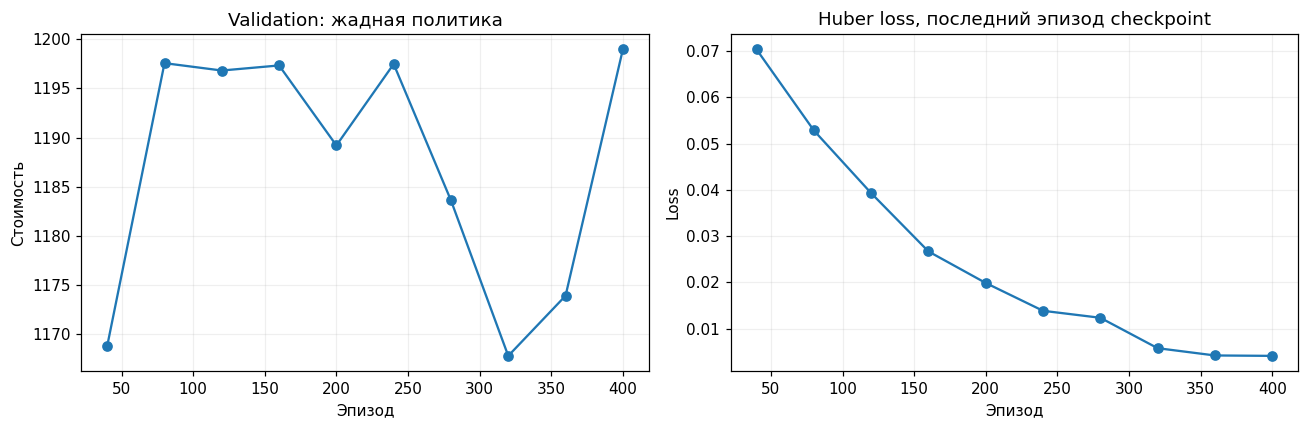

In [3]:
history=pd.read_csv('results/dqn/'+selected['name']+'_history.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(history.episode,history.validation_cost,marker='o');axes[0].set(title='Validation: жадная политика',xlabel='Эпизод',ylabel='Стоимость')
axes[1].plot(history.episode,history.loss,marker='o');axes[1].set(title='Huber loss, последний эпизод checkpoint',xlabel='Эпизод',ylabel='Loss')
fig.tight_layout();fig.savefig('results/dqn_training.png');plt.show()